Nhập các thư viện cần thiết

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


Đọc dữ liệu gốc

In [2]:
dataset = pd.read_csv("../data/raw/Housing.csv")

print("Kích thước dataset:", dataset.shape)
dataset.head()


Kích thước dataset: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


Chia dữ liệu thành Train/Test theo tỉ lệ 80/20

In [3]:
np.random.seed(42)  # cố định seed để kết quả lặp lại được

indices = np.random.permutation(len(dataset))
split = int(0.8 * len(dataset))

train_dataset = dataset.iloc[indices[:split]]
test_dataset = dataset.iloc[indices[split:]]

print("Train:", train_dataset.shape)
print("Test :", test_dataset.shape)


Train: (436, 13)
Test : (109, 13)


Chọn và mã hóa đặc trưng (features)

In [4]:
# Các cột số có sẵn
X_train_raw = train_dataset[["area", "bedrooms", "bathrooms", "stories", "parking"]].copy()
X_test_raw = test_dataset[["area", "bedrooms", "bathrooms", "stories", "parking"]].copy()

# Các cột yes/no chuyển thành 0/1
for col in ["mainroad", "guestroom", "basement", "hotwaterheating",
            "airconditioning", "prefarea"]:
    X_train_raw[col] = (train_dataset[col] == "yes").astype(int)
    X_test_raw[col] = (test_dataset[col] == "yes").astype(int)

# furnishingstatus có 3 giá trị nên dùng one-hot encoding,
# bỏ cột đầu tiên để tránh dummy trap
dummies_train = pd.get_dummies(train_dataset["furnishingstatus"], prefix="furn", drop_first=True)
dummies_test = pd.get_dummies(test_dataset["furnishingstatus"], prefix="furn", drop_first=True)
X_train_raw = pd.concat([X_train_raw, dummies_train.astype(int)], axis=1)
X_test_raw = pd.concat([X_test_raw, dummies_test.astype(int)], axis=1)

y_train = train_dataset["price"].values.reshape(-1, 1)
y_test = test_dataset["price"].values.reshape(-1, 1)

print("X_train:", X_train_raw.shape, "| X_test:", X_test_raw.shape)

# Tương quan giữa các feature với giá, để biết feature nào quan trọng
corr_df = X_train_raw.copy()
corr_df["price"] = y_train.ravel()
corr_df.corr()["price"].drop("price").sort_values(ascending=False).round(3)


X_train: (436, 13) | X_test: (109, 13)


area                   0.528
bathrooms              0.514
airconditioning        0.459
stories                0.430
parking                0.370
bedrooms               0.370
prefarea               0.341
mainroad               0.281
guestroom              0.217
basement               0.164
hotwaterheating        0.093
furn_semi-furnished    0.044
furn_unfurnished      -0.252
Name: price, dtype: float64

Các hàm tự viết

In [5]:
# Hàm tính MSE
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

# Hàm tính R2 = 1 - SS_res / SS_tot
def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

# Hàm tính RMSE
def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

# Thêm cột 1 vào đầu ma trận X để có hệ số bias
def add_bias(X):
    ones = np.ones((X.shape[0], 1))
    return np.concatenate((ones, X), axis=1)

# Gradient Descent dạng batch cho hồi quy tuyến tính
def gradient_descent(X, y, alpha, n_iter):
    theta = np.zeros((X.shape[1], 1))
    n = len(y)
    losses = []

    for i in range(n_iter):
        y_pred = X @ theta
        err = y_pred - y
        grad = (1 / n) * (X.T @ err)   # gradient của hàm MSE
        theta = theta - alpha * grad
        losses.append(mse(y, y_pred))  # lưu loss để vẽ đồ thị hội tụ

    return theta, losses


Phương pháp A: Gradient Descent KHÔNG chuẩn hóa dữ liệu

In [6]:
X_train = add_bias(X_train_raw.to_numpy(dtype=float))
X_test = add_bias(X_test_raw.to_numpy(dtype=float))

# area ~ 1000 trong khi các feature khác chỉ ~ 0-3,
# nên learning rate phải rất nhỏ, nếu lớn thì loss phát nổ
alpha_a = 1e-10
n_iter_a = 20000

theta_a, losses_a = gradient_descent(X_train, y_train, alpha_a, n_iter_a)

print("MSE train (phương pháp A):", "{:.3e}".format(losses_a[-1]))
print("R2  train (phương pháp A):", "{:.4f}".format(r2(y_train, X_train @ theta_a)))


MSE train (phương pháp A): 3.432e+12
R2  train (phương pháp A): 0.0151


Phương pháp B: Gradient Descent CÓ chuẩn hóa dữ liệu (z-score)

In [7]:
# Chuẩn hóa z-score: (x - mean) / std.
# Chỉ tính mean/std từ tập train rồi áp dụng cho cả test (tránh rò rỉ dữ liệu)
mean_X = X_train_raw.to_numpy(dtype=float).mean(axis=0)
std_X = X_train_raw.to_numpy(dtype=float).std(axis=0)

X_train_norm = (X_train_raw.to_numpy(dtype=float) - mean_X) / std_X
X_test_norm = (X_test_raw.to_numpy(dtype=float) - mean_X) / std_X

X_train_norm = add_bias(X_train_norm)
X_test_norm = add_bias(X_test_norm)

# Sau khi chuẩn hóa, các feature cùng thang đo nên dùng learning rate lớn
alpha_b = 0.1
n_iter_b = 1000

theta_b, losses_b = gradient_descent(X_train_norm, y_train, alpha_b, n_iter_b)

print("MSE train (phương pháp B):", "{:.3e}".format(losses_b[-1]))
print("R2  train (phương pháp B):", "{:.4f}".format(r2(y_train, X_train_norm @ theta_b)))


MSE train (phương pháp B): 1.088e+12
R2  train (phương pháp B): 0.6876


Phương pháp C: Nghiệm đóng (normal equation)

In [8]:
# Nghiệm đóng: theta = (X^T X)^(-1) X^T y
theta_c = np.linalg.inv(X_train.T @ X_train) @ X_train.T @ y_train

print("MSE train (phương pháp C):", "{:.3e}".format(mse(y_train, X_train @ theta_c)))
print("R2  train (phương pháp C):", "{:.4f}".format(r2(y_train, X_train @ theta_c)))


MSE train (phương pháp C): 1.088e+12
R2  train (phương pháp C): 0.6876


Biểu đồ 1: Đường cong hội tụ (Training Loss theo số vòng lặp)

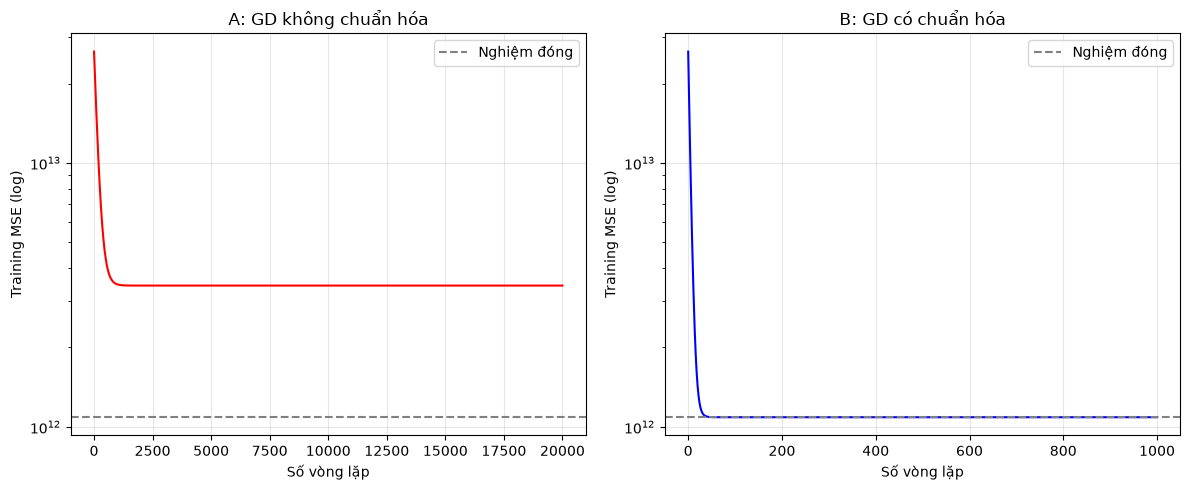

In [9]:
# MSE của nghiệm đóng dùng làm mốc so sánh
cf_mse = mse(y_train, X_train @ theta_c)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Thang log vì loss giảm rất nhanh ở đầu
ax[0].semilogy(losses_a, color="red", linewidth=1.5)
ax[0].axhline(cf_mse, linestyle="--", color="gray", label="Nghiệm đóng")
ax[0].set_xlabel("Số vòng lặp")
ax[0].set_ylabel("Training MSE (log)")
ax[0].set_title("A: GD không chuẩn hóa")
ax[0].legend()
ax[0].grid(True, alpha=0.3)

ax[1].semilogy(losses_b, color="blue", linewidth=1.5)
ax[1].axhline(cf_mse, linestyle="--", color="gray", label="Nghiệm đóng")
ax[1].set_xlabel("Số vòng lặp")
ax[1].set_ylabel("Training MSE (log)")
ax[1].set_title("B: GD có chuẩn hóa")
ax[1].legend()
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Biểu đồ 2: Giá dự đoán vs Giá thực tế trên tập test

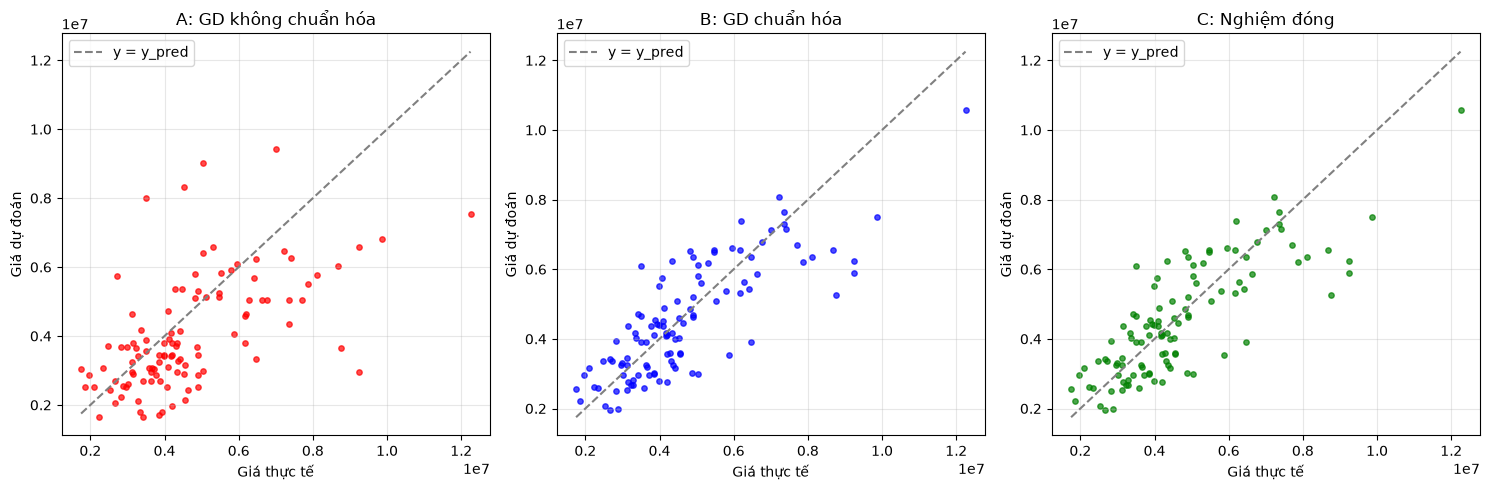

In [10]:
y_pred_a = X_test @ theta_a
y_pred_b = X_test_norm @ theta_b
y_pred_c = X_test @ theta_c

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

for i, (pred, title, color) in enumerate([
    (y_pred_a, "A: GD không chuẩn hóa", "red"),
    (y_pred_b, "B: GD chuẩn hóa", "blue"),
    (y_pred_c, "C: Nghiệm đóng", "green"),
]):
    ax[i].scatter(y_test, pred, s=15, alpha=0.7, color=color)
    ax[i].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
               linestyle="--", color="gray", label="y = y_pred")
    ax[i].set_xlabel("Giá thực tế")
    ax[i].set_ylabel("Giá dự đoán")
    ax[i].set_title(title)
    ax[i].legend()
    ax[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Đánh giá mô hình: MSE, RMSE, R2 trên tập train và test

In [11]:
# Trả về 3 chỉ số dạng chuỗi
def metrics(y_true, y_pred):
    return ("{:.3e}".format(mse(y_true, y_pred)),
            "{:.3e}".format(rmse(y_true, y_pred)),
            "{:.4f}".format(r2(y_true, y_pred)))

results = pd.DataFrame(
    index=["A: GD (không chuẩn hóa)", "B: GD (chuẩn hóa)", "C: Nghiệm đóng"],
    columns=["MSE train", "RMSE train", "R2 train",
             "MSE test", "RMSE test", "R2 test"],
)

results.loc["A: GD (không chuẩn hóa)"] = metrics(y_train, X_train @ theta_a) + metrics(y_test, X_test @ theta_a)
results.loc["B: GD (chuẩn hóa)"] = metrics(y_train, X_train_norm @ theta_b) + metrics(y_test, X_test_norm @ theta_b)
results.loc["C: Nghiệm đóng"] = metrics(y_train, X_train @ theta_c) + metrics(y_test, X_test @ theta_c)

results


,MSE train,RMSE train,R2 train,MSE test,RMSE test,R2 test
A: GD (không chuẩn hóa),3.432e+12,1.853e+06,0.0151,3.031e+12,1.741e+06,0.1369
B: GD (chuẩn hóa),1.088e+12,1.043e+06,0.6876,1.242e+12,1.114e+06,0.6464
C: Nghiệm đóng,1.088e+12,1.043e+06,0.6876,1.242e+12,1.114e+06,0.6464


## Thảo luận và phân tích

### 1. Vì sao chọn các feature này?

Em không chỉ dùng 5 cột số có sẵn (`area`, `bedrooms`, `bathrooms`, `stories`,
`parking`) mà chuyển toàn bộ dữ liệu về dạng số: 6 cột yes/no được mã hóa
thành 0/1, còn `furnishingstatus` được one-hot encoding thành 2 cột (bỏ 1 mức
để tránh dummy trap). Bảng tương quan ở trên cho thấy `area` là feature quan
trọng nhất (tương quan ≈ 0.53 với giá), nhưng các feature nhị phân như
`airconditioning`, `prefarea`, `mainroad` cũng ảnh hưởng rõ rệt. Nếu chỉ dùng
5 cột số thì test R2 chỉ đạt ≈ 0.54, trong khi dùng đủ 13 features thì test
R2 tăng lên ≈ 0.65. Điều này cũng hợp lý về mặt thực tế: nhà rộng hơn, có
điều hòa, ở khu vực ưa thích thì giá cao hơn. Vì tất cả các cột đều được mã
hóa thành số nên mô hình vẫn là hồi quy tuyến tính bình thường.

### 2. Ảnh hưởng của việc chuẩn hóa dữ liệu đến Gradient Descent

Các feature gốc có thang đo rất khác nhau (area ~ 10^3, bedrooms ~ 3, cột
0/1), làm cho hàm loss bị "méo" (ill-conditioned). Ở phương pháp A, em phải
dùng learning rate cực nhỏ (α = 10^-10) vì chỉ cần lớn hơn một chút (cỡ
10^-7) là loss phát nổ thành NaN. Với learning rate nhỏ như vậy, loss giảm
nhanh trong khoảng 1000 vòng lặp đầu (từ 2.6·10^13 xuống còn ≈ 3.4·10^12)
rồi sau đó gần như đứng yên: chạy đủ 20000 vòng mà train R2 chỉ đạt ≈ 0.02,
tức mô hình chẳng khá hơn việc dự đoán bằng giá trung bình là bao.

Sau khi chuẩn hóa z-score (phương pháp B), mọi feature đều cùng thang đo,
hàm loss trở nên "tròn" hơn nên dùng được learning rate lớn (α = 0.1) mà
không sợ phát nổ. GD chỉ mất khoảng 100 vòng lặp (trong tổng số 1000) là đã
đạt đúng nghiệm tối ưu, giống hệt nghiệm đóng (MSE train = 1.088·10^12).
Như vậy, chuẩn hóa dữ liệu giúp GD hội tụ nhanh hơn rất nhiều và ổn định hơn.

### 3. Nghiệm đóng so với Gradient Descent

Nghiệm đóng (normal equation) giải ra theta ngay trong một bước bằng phép
nghịch đảo ma trận (độ phức tạp O(d^3), với d = 14 cột), không cần chọn
learning rate hay số vòng lặp, và cho kết quả chính xác nhất — phương pháp B
và C cho ra kết quả y hệt nhau (train R2 = 0.688, test R2 = 0.646). Gradient
Descent thì phải lặp nhiều vòng (mỗi vòng tốn O(n·d)) và phải tự chọn tham
số; phương pháp A chạy tận 20000 vòng mà kết quả còn tệ hơn nhiều so với một
lần giải nghiệm đóng. GD chỉ thực sự có lợi khi dữ liệu quá lớn, không thể
tính và nghịch đảo X^T X (tốn O(n·d^2) thời gian, O(d^2) bộ nhớ) được. Với
dataset nhỏ như thế này, nghiệm đóng vừa nhanh vừa chính xác nhất trong 3
phương pháp.
